# Citi Bike Demand During G Train Disruptions

## DATA 622 Final Project

This notebook documents the study of Citi Bike demand near G train stations in Greenpoint. It presents the research question, exploration, models and evaluation. It runs on Databricks and reads the Delta tables that scheduled Databricks jobs build and keep up to date. Data preparation (Section 2) is documented in its own notebook, [01_data_preparation.ipynb](01_data_preparation.ipynb). Disruption effects are described only as screening comparisons from confirmed closure windows and are not treated as causal estimates.

## Contents

1. Problem definition: research question and objectives
2. Data preparation: summary and the tables used here (full section in [01_data_preparation.ipynb](01_data_preparation.ipynb))
3. Exploration: exploratory data analysis and feature engineering
   - 3.1 to 3.4 Coverage, daily and hourly demand, stations and availability
   - 3.5 Feature engineering
   - 3.6 to 3.9 Exposure, weather, outcome distribution, dataset readiness and summary
4. Model development
5. Evaluation and validation
6. Production design and monitoring
7. Results and discussion
8. Conclusion
9. References and appendices


### Figure and table standard

Each figure will have a descriptive title, labeled axes, units, and a caption that identifies the data and time period. A short interpretation will follow each figure. It will describe the visible pattern, explain why the pattern matters, and state any limits on what the figure can show. A descriptive pattern alone will not be called a causal effect.

# 1. Problem definition: research question and objectives

## 1.1 Background

Citi Bike provides a transportation option when subway service is disrupted. This project focuses on Greenpoint, where the G train is an important subway connection. A service interruption may change the number and direction of trips near affected stops. It may also leave some stations with too few bikes for departing riders or too few open docks for arriving riders. The size, location, and timing of these changes matter to bike operations staff and public transport planners.

The existing project proposal describes this as a study of G train disruptions and Citi Bike demand. This notebook separates the analysis from the proposal and will document the data and evidence used to answer the question.

## 1.2 Research question and hypotheses

**How does a planned or unplanned G train service disruption relate to Citi Bike trip activity and station availability near affected Greenpoint subway stops, compared with expected conditions when service is operating?**

The word *relate* is deliberate. The primary question is whether demand and availability differ during verified G train disruptions, not whether any difference is automatically caused by the disruption. A causal interpretation requires credible comparison periods, correct event dates, and consideration of other causes such as weather, season, holidays, and routine travel patterns.

The working hypotheses are that trip departures and arrivals will change near affected stations during service interruptions, and that the probability of a station reporting no available bikes or no open docks will also change. These are hypotheses to test, not findings. The direction and size of the changes may differ by station, time of day, and day type.

## 1.3 Objectives and success criteria

1. Describe the trip activity and bike availability patterns at Citi Bike stations near affected G train stops.
2. Compare disruption periods with suitable periods when G train service was operating, while accounting for time, day, weather, and station differences where data allow.
3. Identify stations and time periods that may need extra bikes or open docks during a disruption.
4. Prepare a documented analysis dataset and clear definitions that can support later model development.

The first stage is complete when the study population, event definition, data coverage, cleaning decisions, and station by hour measures are documented; the main temporal and spatial patterns are shown in figures; and each figure has an evidence based interpretation. A claim about a disruption effect will require a separate comparison design and supporting event data.

## 1.4 Scope and intended use

The initial area is screened with a rectangular latitude and longitude boundary around Greenpoint. This is a practical way to identify candidate stations, not an official neighborhood boundary or a definition of exposure to a G train closure. The final exposed station group should be based on measured distance to subway stops affected in each verified event. The local trip files cover May to September 2024 and January to September 2026. Historical station status is available from August 21 to October 1, 2026, and only for Greenpoint. The local weather archive covers May to September 2024 and January to September 2026. A live MTA alert snapshot adds 28 G service event periods from October 19 to November 23, 2026, and none overlap the station status period. The MTA subway alert history currently ends on August 11, 2026, before the station status period, so it cannot identify closure hours in the status sample. Hourly ridership at G stations is used to infer them in the inferred windows subsection of Section 2.2. Citi Bike operations staff and public transport planners are the intended users of later estimates.

## 1.5 Population, exposure, and outcomes

The planned unit of analysis is one Citi Bike station in one local clock hour. The initial population is the set of stations inside the Greenpoint screening boundary that can be matched to station information. The exposure is whether a station is near a subway stop during a verified period when the G train is not operating. The exposure cannot be assigned from the trip and station data alone.

The primary outcomes are the number of departures and arrivals recorded for a station hour. Secondary outcomes describe availability from station status reports: mean reported bikes available, mean reported docks available, and the share of status observations reporting zero bikes or zero docks. A trip count measures completed journeys; a station status report measures inventory at a snapshot. They are complementary outcomes and will not be treated as equivalent measures of demand.

# 2. Data preparation

The data is collected and cleaned in Databricks, not in this notebook. Three scheduled jobs download the raw data into a Unity Catalog volume (`citibike-download` for the monthly trip archives, `external-data-download` for the MTA, weather and Citi Bike station feeds) and `citibike-prepare` cleans it into Delta tables in `workspace.citibike`. The full section is in [01_data_preparation.ipynb](01_data_preparation.ipynb): the pipeline and its jobs, the cleaning rules, every table in the catalog, the data sources (2.1), the confirmed closure windows (2.2.1), the quality checks (2.3) and how the analysis tables are built (2.4 to 2.6). References to Sections 2.1 to 2.6 below point to that notebook.

This notebook reads the prepared tables only, so it can be run on its own:

| Table | Used in | Content |
|---|---|---|
| `analysis_station_hour_panel_extended` | 3, 4, 5 | Main modeling table: 153 stations by hour for May to September 2024 and January to September 2026, with outcomes, weather, calendar, closure flags, baseline, profile and split |
| `analysis_station_hour_panel` | 3 | Greenpoint stations by hour, August and September 2026, with station availability |
| `trip_hourly_model_stations` | 3 | Hourly departures and arrivals per model station for the 14 study months |
| `stations`, `station_status_hourly` | 3 | Greenpoint stations and their hourly availability |
| `model_station_sets`, `model_station_g_stop_distances`, `mta_g_stops` | 3 | Corridor and control stations, distances to G stops and the affected segment (exposure map) |
| `g_service_closures_confirmed`, `g_service_closures_confirmed_pre_august` | 3 | The 2026 closure weekends marked in the figures |

In [1]:
%pip install -q lightgbm


Note: you may need to restart the kernel to use updated packages.


### Notebook setup

The next cell makes the project package `src/citibike` importable, reads the catalog, schema and volume settings and opens the Spark session. The cell after it loads the tables listed above.

In [2]:
import sys
from pathlib import Path

# Make src/ importable: walk up from this notebook to the folder that holds databricks.yml.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "databricks.yml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError(f"Could not find the project root (databricks.yml) above {Path.cwd()}")
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
from citibike import data_access, study
from citibike import transformations as tf
from citibike.notebook import connect

# Catalog, schema and volume (notebook widgets in Databricks, CITIBIKE_* environment variables or defaults elsewhere),
# the Spark session, and read_table(name, columns, where) to load a project table as pandas
CONFIG, spark, read_table = connect(globals().get("dbutils"))

c:\Users\simon\OneDrive\Documents\GitHub\data622_nyc_bikes_project\.venv\Lib\site-packages\databricks\sdk\_widgets\__init__.py:70: UserWarning: 
To use databricks widgets interactively in your notebook, please install databricks sdk using:
	pip install 'databricks-sdk[notebook]'
Falling back to default_value_only implementation for databricks widgets.
  warnings.warn(


In [3]:
# Tables used by Sections 3 to 6 (built by the citibike-prepare job, documented in 01_data_preparation.ipynb)
panel = read_table("analysis_station_hour_panel").sort_values(["station_id", "hour"]).reset_index(drop=True)
panel["distance_band"] = tf.as_distance_band(panel["distance_band"])
panel_extended = (
    read_table("analysis_station_hour_panel_extended")
    .sort_values(["short_name", "period", "hour"]).reset_index(drop=True)
)

# Hourly trips per model station for the 14 study months (counted per trip file month, summed per hour)
trip_hourly = (
    read_table("trip_hourly_model_stations")
    .groupby(["short_name", "hour"], as_index=False)[["departures", "arrivals"]].sum()
    .sort_values(["short_name", "hour"]).reset_index(drop=True)
)
trip_hourly["month"] = trip_hourly["hour"].dt.to_period("M").astype(str)

# Greenpoint stations (latest snapshot) and their hourly availability
stations = read_table("stations").sort_values("station_id").reset_index(drop=True)
stations["station_id"] = stations["station_id"].astype("string")
stations["short_name"] = stations["short_name"].astype("string")
greenpoint_stations = stations[stations["in_greenpoint_screen"]].copy()
greenpoint_stations["trip_station_id"] = greenpoint_stations["short_name"]
id_list = ", ".join(f"'{station_id}'" for station_id in greenpoint_stations["station_id"])
greenpoint_station_status = read_table("station_status_hourly", where=f"station_id IN ({id_list})")
greenpoint_station_status["station_id"] = greenpoint_station_status["station_id"].astype("string")
greenpoint_status = tf.greenpoint_status_frame(
    greenpoint_station_status.sort_values(["station_id", "hour"]).reset_index(drop=True), greenpoint_stations
)

# G stops, the affected segment, model stations and their distances to G stops
mta_g_stops = read_table("mta_g_stops").sort_values(["stop_name", "gtfs_stop_id"]).reset_index(drop=True)
segment_stop_ids = mta_g_stops.loc[mta_g_stops["affected_segment"], "gtfs_stop_id"].sort_values()
model_stations = read_table("model_station_sets").sort_values(["station_group", "short_name"]).reset_index(drop=True)
model_pairs = read_table("model_station_g_stop_distances")

# Confirmed G closure weekends
g_confirmed_windows = read_table("g_service_closures_confirmed").sort_values("start_local").reset_index(drop=True)
g_confirmed_pre_august = (
    read_table("g_service_closures_confirmed_pre_august").sort_values("start_local").reset_index(drop=True)
)

display(pd.DataFrame([
    ("analysis_station_hour_panel_extended", len(panel_extended)),
    ("analysis_station_hour_panel", len(panel)),
    ("trip_hourly_model_stations (station hours)", len(trip_hourly)),
    ("Greenpoint stations / status station hours", f"{len(greenpoint_stations)} / {len(greenpoint_status):,}"),
    ("model stations / G stops", f"{len(model_stations)} / {len(mta_g_stops)}"),
    ("confirmed closure weekends", len(g_confirmed_windows) + len(g_confirmed_pre_august)),
], columns=["Loaded", "Rows"]))

,Loaded,Rows
0,analysis_station_hour_panel_extended,1485072
1,analysis_station_hour_panel,62952
2,trip_hourly_model_stations (station hours),917942
3,Greenpoint stations / status station hours,"43 / 42,243"
4,model stations / G stops,154 / 21
5,confirmed closure weekends,13


# 3. Exploration: exploratory data analysis and feature engineering

Exploratory analysis will describe the data before any predictive or causal model is fit. Tables and plots will include the sample size, time span, and aggregation level needed to interpret them. Every plot in this section is generated from the project tables in Databricks, states its sample and time span, and is followed by an interpretation.

## 3.1 Coverage, data quality, and study period

The data quality table in [Section 2](01_data_preparation.ipynb) reports source rows, excluded endpoint records, station identifiers that do not match the latest station file, and the overlap between trip and status hours. The trip records used for the area figures cover May to September 2024 and January to September 2026 (hourly counts built in [Section 2.6](01_data_preparation.ipynb)). Historical station status covers August 21 through October 1, 2026. Weather observations cover the same trip months, and the subway stop lookup provides coordinates for G train stops. MTA alert updates currently end on August 11, 2026, before the status sample, and the live alert snapshot only lists G work from October 19, 2026. Some rides in each trip archive start or end just outside the month in its file name, so the timestamp of each measured event defines the analysis period. Closure intervals are taken from MTA planned service notices for 13 weekends in 2026 ([Section 2.2.1](01_data_preparation.ipynb)) and from the 2024 shutdown phases ([Section 2.6](01_data_preparation.ipynb)). Only the three weekends from August 21 onward overlap station status.

Trip records from August 21 to September 30, 2026 overlap with station status in time. Trips in the other months do not have matching historical station status in the available data, and status continues beyond the trip period. The two sources are therefore analyzed separately except where station and hour keys match. This prevents a missing record in one source from being interpreted as a measured zero in another.

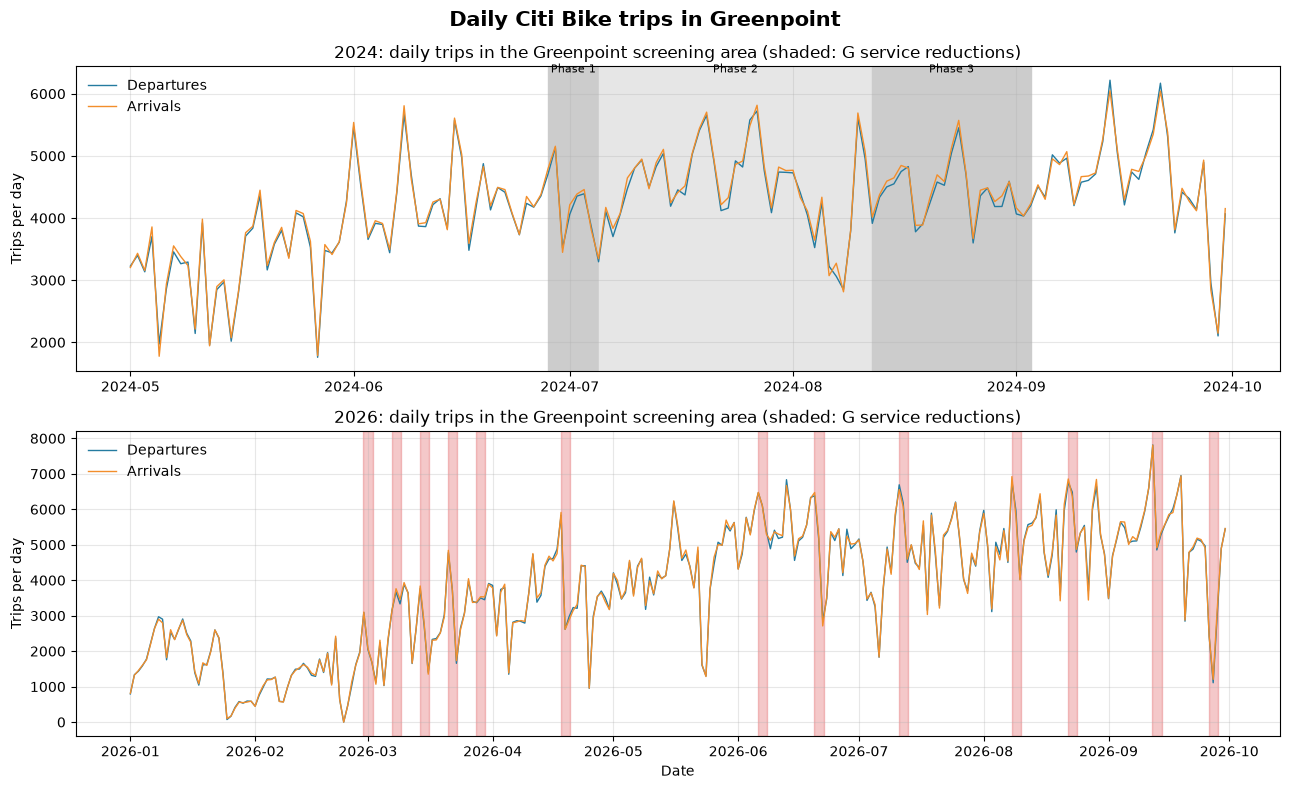

,departures,arrivals,calendar days,mean departures per day,mean arrivals per day
2024-05,100989,102035,31,3257.7,3291.5
2024-06,129800,130818,30,4326.7,4360.6
2024-07,142068,143659,31,4582.8,4634.2
2024-08,132960,134814,31,4289.0,4348.8
2024-09,136802,137216,30,4560.1,4573.9
2026-01,51589,51478,31,1664.2,1660.6
2026-02,35531,35696,28,1269.0,1274.9
2026-03,87991,88533,31,2838.4,2855.9
2026-04,104813,104741,30,3493.8,3491.4
2026-05,132106,133062,31,4261.5,4292.3


In [4]:
import matplotlib.pyplot as plt

# Area totals for the 43 Greenpoint stations over all extended trip months (2024 and 2026)
area_codes = set(greenpoint_stations["trip_station_id"].dropna())
area_hourly_all = (
    trip_hourly[trip_hourly["short_name"].isin(area_codes)]
    .groupby("hour")[["departures", "arrivals"]].sum()
)
MONTHS_FOR_EXPLORATION = tuple(
    [f"2024-{month:02d}" for month in range(5, 10)] + [f"2026-{month:02d}" for month in range(1, 10)]
)
monthly_hourly = {}
monthly_daily = {}
for month in MONTHS_FOR_EXPLORATION:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthBegin(1)
    hour_index = pd.date_range(month_start, month_end, freq="h", inclusive="left")
    hourly = area_hourly_all.reindex(hour_index, fill_value=0)
    monthly_hourly[month] = hourly
    monthly_daily[month] = hourly.resample("D").sum()

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for axis, year in zip(axes, ("2024", "2026")):
    daily = pd.concat([monthly_daily[m] for m in MONTHS_FOR_EXPLORATION if m.startswith(year)])
    axis.plot(daily.index, daily["departures"], label="Departures", color="#247ba0", linewidth=1)
    axis.plot(daily.index, daily["arrivals"], label="Arrivals", color="#f28e2b", linewidth=1)
    if year == "2024":
        for label, start, end, shade in (("Phase 1", "2024-06-28", "2024-07-05", "0.8"),
                                         ("Phase 2", "2024-07-05", "2024-08-12", "0.9"),
                                         ("Phase 3", "2024-08-12", "2024-09-03", "0.8")):
            axis.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=shade, zorder=0)
            axis.text(pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2,
                      daily[["departures", "arrivals"]].max().max() * 1.02, label, ha="center", fontsize=8)
    else:
        for window in pd.concat([g_confirmed_pre_august[["start_local", "end_local"]],
                                 g_confirmed_windows[["start_local", "end_local"]]]).itertuples():
            axis.axvspan(window.start_local, window.end_local, color="tab:red", alpha=0.25, zorder=0)
    axis.set_title(f"{year}: daily trips in the Greenpoint screening area (shaded: G service reductions)")
    axis.set_ylabel("Trips per day")
    axis.grid(alpha=0.3)
    axis.legend(frameon=False, loc="upper left")
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Citi Bike trips in Greenpoint", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

daily_totals = pd.DataFrame(
    {month: monthly_daily[month][["departures", "arrivals"]].sum() for month in MONTHS_FOR_EXPLORATION}
).T
daily_totals["calendar days"] = [len(monthly_daily[month]) for month in MONTHS_FOR_EXPLORATION]
daily_totals["mean departures per day"] = daily_totals["departures"] / daily_totals["calendar days"]
daily_totals["mean arrivals per day"] = daily_totals["arrivals"] / daily_totals["calendar days"]
display(daily_totals.round(1))

**Figure 1. Daily Citi Bike departures and arrivals in the Greenpoint screening area, May to September 2024 and January to September 2026.** The top panel shows 2024 and the bottom panel shows 2026, with counts assigned by the recorded trip start and end times. Gray bands in the top panel mark the three phases of the 2024 G shutdown. Red bands in the bottom panel mark the 13 confirmed 2026 weekend closures. The months between October 2024 and December 2025 are not part of the study data, so they are not shown.

**Interpretation.** Demand follows a strong seasonal cycle. Mean departures per day rise from 1,269 in February 2026, the lowest month, to 5,268 in August 2026, the highest. Within 2024, mean daily departures grew from 3,258 in May to 4,583 in July and stayed near 4,300 to 4,600 through September. Arrivals track departures closely in every month (the two lines almost overlap), which is expected for a set of stations where bikes that leave are returned nearby, so the net flow of the area is small. The same months are higher in 2026 than in 2024 (June 5,253 against 4,327 departures per day, and September 5,035 against 4,560), which is consistent with system growth, with more stations (40 active in 2024, 43 in August and September 2026) and with different weather. The repeated waves are the weekly cycle of weekdays and weekends. The closure bands run from Friday night to Monday morning, so they sit on the weekend part of that cycle, and no lasting change in the level of the series is visible after them. Several days in late January 2026 have close to zero trips, and 2026 has a clear dip at the end of September. The causes were not investigated here, and such days will matter for the weather controls in later models. Area totals hide differences between stations, so these plots cannot show whether stations near a closed stop behaved differently. That comparison is made at the station level in [Section 2.6](01_data_preparation.ipynb) and in Section 3.6. The station count also changes between months (for example 36 active stations in July 2026), so month to month comparisons mix demand changes with availability of stations.

## 3.2 Daily and hourly demand patterns

Figure 1 summarizes daily departures and arrivals in the Greenpoint screening area. Figure 2 compares average area wide activity by local hour and day type. Each month is shown separately because seasonal conditions differ. These are descriptive summaries across selected stations, not individual rider behavior.

The daily figure above shows total volume by date. The next figure examines how this activity is distributed across the hours of a typical weekday and weekend day.

## 3.3 Hourly demand profiles

Hourly profiles use the complete calendar grid for each of the 14 months, with unobserved station hour counts represented as zero only inside the local area wide trip totals. The next subsection examines spatial differences and the separate station inventory records.

**Figure 2. Average hourly trips by day type.** The left panel shows weekdays and the right panel shows weekends. Each line is one month from May to September 2024 (dashed) and January to September 2026 (solid), colored from the earliest to the latest month. The lines show mean total departures plus arrivals per clock hour across the Greenpoint screening area. Hours without a recorded area wide trip are included as zero within each calendar month.

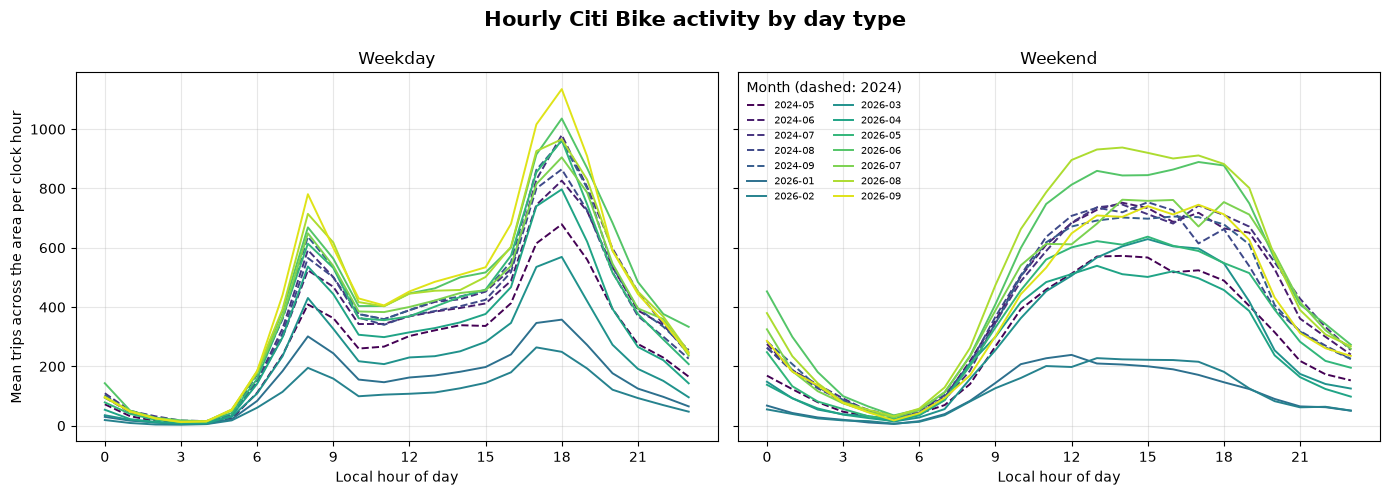

peak local hour         mean trips at peak        
day type         Weekday Weekend            Weekday Weekend
month                                                      
2024-05             18.0    14.0              679.0   572.6
2024-06             18.0    14.0              826.2   751.8
2024-07             18.0    14.0              980.2   745.8
2024-08             18.0    15.0              864.5   753.4
2024-09             18.0    16.0              961.2   705.4
2026-01             18.0    12.0              357.6   238.8
2026-02             17.0    13.0              264.1   227.9
2026-03             18.0    15.0              569.1   629.2
2026-04             18.0    13.0              797.0   539.1
2026-05             18.0    15.0              962.4   637.4
2026-06             18.0    17.0             1035.7   889.1
2026-07             18.0    14.0              904.8   762.0
2026-08             18.0    14.0              965.8   938.0
2026-09             18.0    17.0             1134.9   745.0

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
hourly_profiles = {}
peak_rows = []
colors = dict(zip(MONTHS_FOR_EXPLORATION, plt.cm.viridis(np.linspace(0, 0.95, len(MONTHS_FOR_EXPLORATION)))))

for month in MONTHS_FOR_EXPLORATION:
    hourly = monthly_hourly[month].copy()
    hourly["day_type"] = hourly.index.dayofweek.map(lambda day: "Weekend" if day >= 5 else "Weekday")
    hourly["hour_of_day"] = hourly.index.hour
    hourly["trips"] = hourly["departures"] + hourly["arrivals"]
    profile = hourly.groupby(["day_type", "hour_of_day"], observed=True)["trips"].mean().unstack("day_type")
    hourly_profiles[month] = profile
    for axis, day_type in zip(axes, ("Weekday", "Weekend")):
        axis.plot(profile.index, profile[day_type], color=colors[month], linewidth=1.4,
                  linestyle="--" if month.startswith("2024") else "-", label=month)
        peak_hour = profile[day_type].idxmax()
        peak_rows.append({"month": month, "day type": day_type, "peak local hour": int(peak_hour),
                          "mean trips at peak": round(float(profile.loc[peak_hour, day_type]), 1)})
for axis, day_type in zip(axes, ("Weekday", "Weekend")):
    axis.set_title(day_type)
    axis.set_xlabel("Local hour of day")
    axis.set_xticks(range(0, 24, 3))
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Mean trips across the area per clock hour")
axes[1].legend(frameon=False, fontsize=7, ncol=2, title="Month (dashed: 2024)", loc="upper left")
fig.suptitle("Hourly Citi Bike activity by day type", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

display(pd.DataFrame(peak_rows).pivot(index="month", columns="day type", values=["peak local hour", "mean trips at peak"]))

**Figure 2 interpretation.** The weekday profile has the same shape in every month: demand is low overnight, rises through the morning, and reaches its daily peak at 18:00 in 13 of the 14 months (17:00 in February 2026). The mean combined trips at the weekday peak range from 264 in February 2026 to 1,135 in September 2026. A morning peak at 08:00 is also clear and reaches roughly 60 to 70 percent of the evening peak, which is the commuter pattern of a residential area. The weekend profile has a single broad midday and afternoon hump, with its peak between 12:00 and 17:00, and in summer months more trips after midnight, with a peak of 239 in January 2026 and 938 in August 2026. The dashed 2024 lines have the same weekday shape as the 2026 lines, so the daily rhythm is stable across years and the 2024 data can be used as an external check of the shutdown effect. The curves rise from winter to late summer, which is the seasonal pattern also seen in Figure 1. These area summaries show when trip activity was highest in this sample, not why it was high. The hourly means include hours with no area trips. They do not control for weather or for the number of active stations, and the table of peak hours and peak means by month is the numeric form of the figure.

## 3.4 Spatial demand, station availability, and disruption limits

Station identifiers are matched to the latest station information snapshot, and station by hour keys are checked before plotting. Figure 3 ranks Greenpoint stations by total departures plus arrivals from January to September 2026 and checks whether the ranking held in summer 2024. Figure 4 measures the share of observed status snapshots with no open docks. A station with no bikes is a separate condition from one with no open docks. Station status exists only for August 21 to September 30, 2026, so Figure 4 cannot be extended to earlier months. The confirmed closure windows are linked to Citi Bike stations with a quarter mile distance rule in Sections 3.5 and 3.6, where the disruption comparison is made. That comparison is descriptive and is not a causal estimate.

**Figure 3. Station volume and stability across years.** The left panel ranks the ten busiest Greenpoint stations by departures plus arrivals from January to September 2026, with departures and arrivals stacked. The right panel compares the mean daily trips of the same stations in June to September 2024 and 2026.

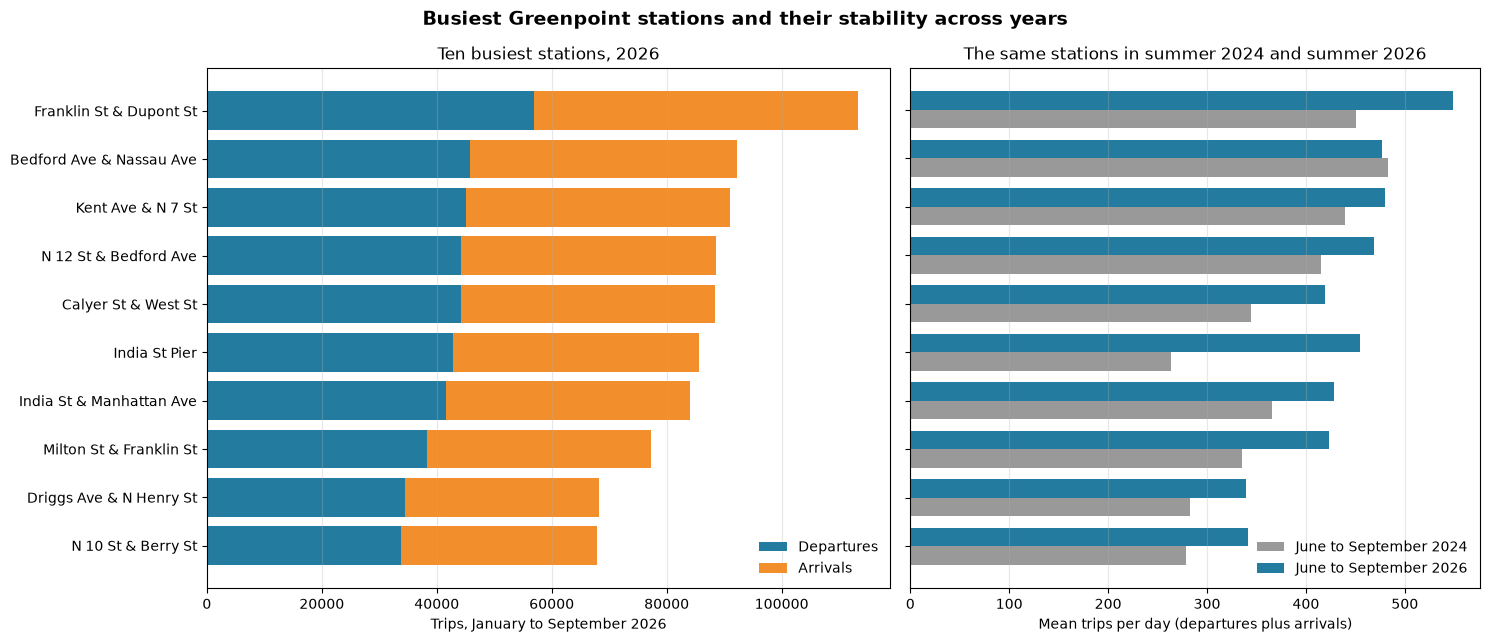

,departures,arrivals,total trips,share of area trips,"mean daily trips, summer 2024","mean daily trips, summer 2026"
name,,,,,,
Franklin St & Dupont St,56872,56397,113269,0.055,450.426,548.582
Bedford Ave & Nassau Ave,45847,46472,92319,0.045,482.697,476.730
Kent Ave & N 7 St,45095,45845,90940,0.044,439.254,479.893
N 12 St & Bedford Ave,44157,44382,88539,0.043,415.320,468.459
Calyer St & West St,44166,44242,88408,0.043,344.590,419.156
India St Pier,42772,42928,85700,0.042,263.107,454.451
India St & Manhattan Ave,41672,42299,83971,0.041,365.861,428.656
Milton St & Franklin St,38379,38859,77238,0.038,335.434,423.648
Driggs Ave & N Henry St,34495,33751,68246,0.033,283.197,339.484


Rank correlation of station volume, summer 2024 and summer 2026 (40 stations active in both): 0.894
Top ten stations in 2026 that were also in the top ten in summer 2024: 7 of 10
Share of all area trips at the ten busiest stations: 41.6%


In [6]:
# Station ranking over all 2026 months, and the stability of the busiest stations against summer 2024
name_by_code = greenpoint_stations.set_index("trip_station_id")["name"]
area_trips = trip_hourly[trip_hourly["short_name"].isin(name_by_code.index)].copy()
area_trips["name"] = area_trips["short_name"].map(name_by_code)
trips_2026 = area_trips[area_trips["hour"].between("2026-01-01", "2026-09-30 23:00")]
ranking_2026 = trips_2026.groupby("name")[["departures", "arrivals"]].sum()
ranking_2026["total trips"] = ranking_2026["departures"] + ranking_2026["arrivals"]
top_stations = ranking_2026.nlargest(10, "total trips").sort_values("total trips")

def summer_daily_mean(frame, start, end):
    window = frame[frame["hour"].between(start, end + " 23:00")]
    days = (pd.Timestamp(end) - pd.Timestamp(start)).days + 1
    return (window.groupby("name")[["departures", "arrivals"]].sum().sum(axis=1) / days)
summer_2024 = summer_daily_mean(area_trips, "2024-06-01", "2024-09-30").reindex(top_stations.index).fillna(0)
summer_2026 = summer_daily_mean(area_trips, "2026-06-01", "2026-09-30").reindex(top_stations.index).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
positions = np.arange(len(top_stations))
axes[0].barh(positions, top_stations["departures"], label="Departures", color="#247ba0")
axes[0].barh(positions, top_stations["arrivals"], left=top_stations["departures"], label="Arrivals", color="#f28e2b")
axes[0].set_yticks(positions, top_stations.index)
axes[0].set_xlabel("Trips, January to September 2026")
axes[0].set_title("Ten busiest stations, 2026")
axes[0].legend(frameon=False)
height = 0.38
axes[1].barh(positions - height / 2, summer_2024, height, label="June to September 2024", color="0.6")
axes[1].barh(positions + height / 2, summer_2026, height, label="June to September 2026", color="#247ba0")
axes[1].set_yticks(positions, [""] * len(positions))
axes[1].set_xlabel("Mean trips per day (departures plus arrivals)")
axes[1].set_title("The same stations in summer 2024 and summer 2026")
axes[1].legend(frameon=False)
for axis in axes:
    axis.grid(alpha=0.3, axis="x")
fig.suptitle("Busiest Greenpoint stations and their stability across years", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

top_table = top_stations.sort_values("total trips", ascending=False).copy()
top_table["share of area trips"] = top_table["total trips"] / ranking_2026["total trips"].sum()
top_table["mean daily trips, summer 2024"] = summer_2024
top_table["mean daily trips, summer 2026"] = summer_2026
display(top_table.round(3))
rank_2024 = summer_daily_mean(area_trips, "2024-06-01", "2024-09-30")
rank_2026 = summer_daily_mean(area_trips, "2026-06-01", "2026-09-30")
common = rank_2024.index.intersection(rank_2026.index)
print(f"Rank correlation of station volume, summer 2024 and summer 2026 ({len(common)} stations active in both): "
      f"{rank_2024[common].rank().corr(rank_2026[common].rank()):.3f}")
print(f"Top ten stations in 2026 that were also in the top ten in summer 2024: "
      f"{len(set(top_stations.index) & set(rank_2024.nlargest(10).index))} of 10")
print(f"Share of all area trips at the ten busiest stations: {top_stations['total trips'].sum() / ranking_2026['total trips'].sum():.1%}")



**Figure 3 interpretation.** Franklin St & Dupont St is the busiest station with 113,269 trips (56,872 departures and 56,397 arrivals), followed by Bedford Ave & Nassau Ave with 92,319 and Kent Ave & N 7 St with 90,940. The ten stations carry 41.6 percent of all trips in the area, so demand is concentrated. Departures and arrivals are nearly equal at every station, which means these stations are not persistent sources or sinks over the full period. The right panel shows stability: the rank correlation of station volume between summer 2024 and summer 2026 is 0.894 across the 40 stations active in both, and seven of the ten leading stations were already in the top ten in 2024. Volume rose at most stations, most strongly at India St Pier (263 to 454 mean daily trips). The ranking therefore supports using station level baselines across both years, but it does not identify which stations were affected by a closure.

**Figure 4. Share of station status snapshots reporting no open docks.** The figure compares weekdays and weekends by local hour over the available station status period, August 21 through October 1, 2026. The denominator is the number of station status observations, not the number of stations.

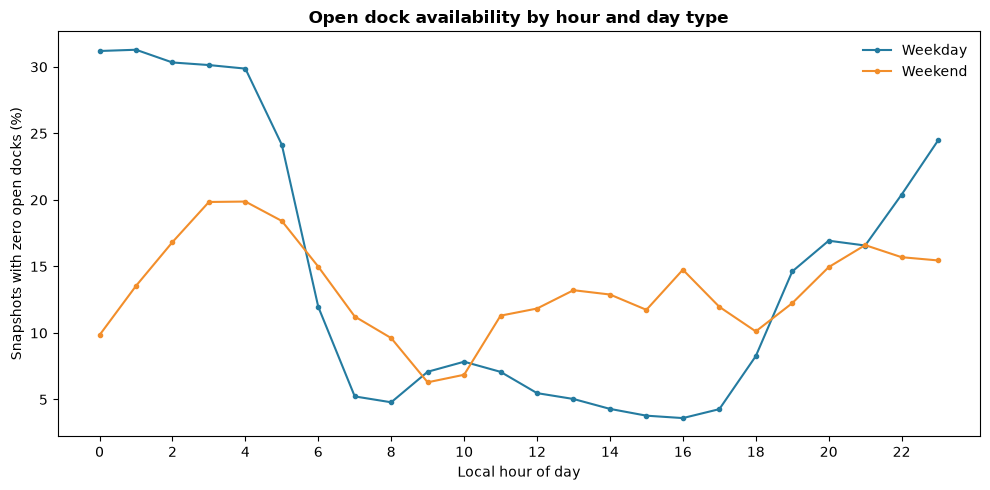

Overall snapshot shares by day type


,zero dock percent,zero bike percent,snapshots
day_type,,,
Weekday,14.56,1.64,357607.0
Weekend,13.34,0.71,148032.0


In [7]:
availability_profile = (
    greenpoint_status.groupby(["day_type", "hour_of_day"], observed=True)
    .agg(
        zero_dock_snapshots=("zero_dock_snapshots", "sum"),
        zero_bike_snapshots=("zero_bike_snapshots", "sum"),
        snapshots=("snapshot_count", "sum"),
    )
)
availability_profile["zero dock percent"] = (
    100 * availability_profile["zero_dock_snapshots"] / availability_profile["snapshots"]
)
availability_profile["zero bike percent"] = (
    100 * availability_profile["zero_bike_snapshots"] / availability_profile["snapshots"]
)

fig, axis = plt.subplots(figsize=(10, 5))
for day_type, color in (("Weekday", "#247ba0"), ("Weekend", "#f28e2b")):
    series = availability_profile.xs(day_type, level="day_type")["zero dock percent"]
    axis.plot(series.index, series, marker="o", markersize=3, label=day_type, color=color)
axis.set_xlabel("Local hour of day")
axis.set_ylabel("Snapshots with zero open docks (%)")
axis.set_xticks(range(0, 24, 2))
axis.set_title("Open dock availability by hour and day type", fontweight="bold")
axis.legend(frameon=False)
fig.tight_layout()
plt.show()

print("Overall snapshot shares by day type")
display(availability_profile.groupby(level="day_type").apply(
    lambda group: pd.Series({
        "zero dock percent": 100 * group["zero_dock_snapshots"].sum() / group["snapshots"].sum(),
        "zero bike percent": 100 * group["zero_bike_snapshots"].sum() / group["snapshots"].sum(),
        "snapshots": group["snapshots"].sum(),
    })
).round(2))

**Figure 4 interpretation.** Across the collected snapshots, zero open docks were reported in 14.56% of weekday observations and 13.34% of weekend observations. Zero bikes were less common, at 1.64% and 0.71%, respectively. This suggests that the observed inventory constraint was more often a lack of return capacity than a lack of bikes, within this station screen and period. These percentages describe snapshots, not every moment between feed updates, and they do not show that a subway closure caused the inventory pattern.

## 3.5 Feature engineering

The preparation cell creates calendar features from the local event time and joins current station attributes using station identifiers. Candidate features for later modeling include:

1. **Hour of day.** The local hour from the analysis timestamp represents daily travel patterns. Confirm local time and daylight saving handling.
2. **Day of week.** The local weekday separates weekday and weekend travel. Confirm category ordering and holidays.
3. **Weekend indicator.** Whether the date falls on Saturday or Sunday provides a simple day type summary. Compare with a full weekday category.
4. **Station attributes.** Location and capacity represent differences in station setting and size. Check dated capacity and identifier matches.
5. **Weather measures.** Temperature and precipitation from the historical archive may account for travel conditions. The station to grid lookup follows the supplied Citi Bike pipeline reference. Check units, local time, spatial resolution, coverage, and missingness before modeling.
6. **Service disruption indicator.** Whether a verified event affects a station and hour identifies event timing and exposure. Use actual service times, not notice publication time alone.
7. **Distance to affected stop.** Geographic distance allows effects to vary with proximity. State the distance method and test more than one threshold.
8. **Recent demand summaries.** Past station activity represents local demand history. Use only information available at prediction time and prevent future data leakage.

The calendar features created for exploration are local hour, weekday, weekday or weekend, date, and calendar month. They describe regular time patterns and support the figures above. Weather, closure flags (`g_closure_hour`, `exposed_closure_hour`), distance to the nearest affected stop, lags and the weekly baseline are joined in the panels of [Sections 2.5 and 2.6](01_data_preparation.ipynb). Any later model feature must be available at forecast time. Station status measures describe reported inventory, not trip counts.

## 3.6 Exposure map and the effect of confirmed G reductions

Figure 5 maps the exposure definition for the 94 corridor stations. Figure 6 then compares exposed, other corridor and control stations during 2026 weekend hours with and without a confirmed G reduction, using the 13 confirmed weekends, dry hours only and excluding holidays. The comparison uses only hours of the day that occur in a closure window, so that the groups cover the same clock hours. The outcome is the ratio of actual trips to each station's normal profile for the same weekday and hour. The comparison is descriptive: it does not adjust for events or station differences.

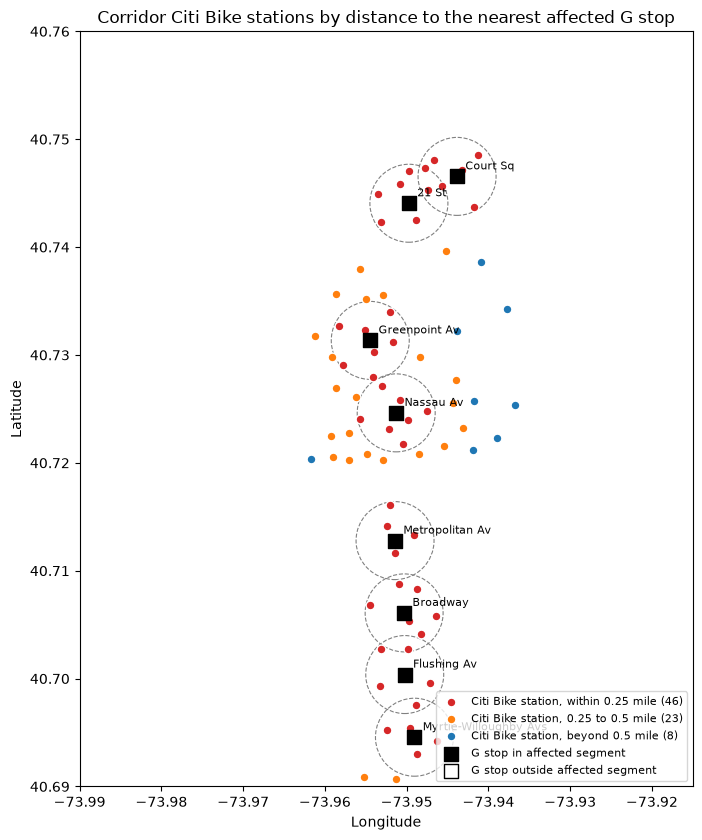

Corridor stations in the map window: 77 of 94
Within 0.25 mile of the affected segment: 46 (14 in the Greenpoint screen)


,stations,mean_capacity,median_miles
distance_band,,,
Within 0.25 mile,46,29.20,0.18
0.25 to 0.5 mile,24,34.46,0.37
Beyond 0.5 mile,24,31.21,0.91


In [8]:
from matplotlib.patches import Ellipse

# Distance from every model station (corridor group) to the nearest stop of the affected 2026 segment
segment_pairs = model_pairs[model_pairs["gtfs_stop_id"].isin(segment_stop_ids)]
map_stations = model_stations.merge(
    segment_pairs.groupby("short_name")["distance_miles"].min().rename("segment_miles"),
    on="short_name", how="left",
)
map_stations = map_stations[map_stations["station_group"].eq("corridor")].copy()
map_stations["distance_band"] = pd.cut(
    map_stations["segment_miles"], [0, 0.25, 0.5, np.inf],
    labels=["Within 0.25 mile", "0.25 to 0.5 mile", "Beyond 0.5 mile"], include_lowest=True,
)
map_stations["in_greenpoint_screen"] = map_stations["short_name"].isin(greenpoint_stations["short_name"])

fig, ax = plt.subplots(figsize=(8.5, 8.5))
band_colors = {"Within 0.25 mile": "tab:red", "0.25 to 0.5 mile": "tab:orange", "Beyond 0.5 mile": "tab:blue"}
view = dict(lat=(40.690, 40.760), lon=(-73.990, -73.915))
visible = map_stations[map_stations["lat"].between(*view["lat"]) & map_stations["lon"].between(*view["lon"])]
for band, color in band_colors.items():
    subset = visible[visible["distance_band"] == band]
    ax.scatter(subset["lon"], subset["lat"], s=40, color=color, edgecolor="white",
               label=f"Citi Bike station, {band.lower()} ({len(subset)})", zorder=3)

near_area = mta_g_stops[mta_g_stops["gtfs_latitude"].between(*view["lat"]) & mta_g_stops["gtfs_longitude"].between(*view["lon"])]
affected_near = near_area[near_area["affected_segment"]]
unaffected_near = near_area[~near_area["affected_segment"]]
ax.scatter(affected_near["gtfs_longitude"], affected_near["gtfs_latitude"], marker="s", s=90, color="black", label="G stop in affected segment", zorder=4)
ax.scatter(unaffected_near["gtfs_longitude"], unaffected_near["gtfs_latitude"], marker="s", s=90, facecolor="white", edgecolor="black", label="G stop outside affected segment", zorder=4)
for stop in affected_near.itertuples():
    ax.annotate(stop.stop_name, (stop.gtfs_longitude, stop.gtfs_latitude), textcoords="offset points", xytext=(6, 5), fontsize=8)
    radius_lat = 0.402336 / 111.32
    radius_lon = 0.402336 / (111.32 * np.cos(np.radians(stop.gtfs_latitude)))
    ax.add_patch(Ellipse((stop.gtfs_longitude, stop.gtfs_latitude), 2 * radius_lon, 2 * radius_lat, fill=False, linestyle="--", color="gray", linewidth=0.8))

ax.set_xlim(*view["lon"])
ax.set_ylim(*view["lat"])
ax.set_aspect(1 / np.cos(np.radians(40.725)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Corridor Citi Bike stations by distance to the nearest affected G stop")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

print(f"Corridor stations in the map window: {len(visible)} of {len(map_stations)}")
print(f"Within 0.25 mile of the affected segment: {int(map_stations['distance_band'].eq('Within 0.25 mile').sum())} "
      f"({int((map_stations['distance_band'].eq('Within 0.25 mile') & map_stations['in_greenpoint_screen']).sum())} in the Greenpoint screen)")
display(map_stations.groupby("distance_band", observed=True).agg(
    stations=("short_name", "size"), mean_capacity=("capacity", "mean"),
    median_miles=("segment_miles", "median")).round(2))


**Interpretation of Figure 5.** The map shows the 77 of the 94 corridor model stations that fall inside the plotted window, colored by distance to the nearest stop of the affected G segment (Court Sq to Bedford-Nostrand Avs), with quarter mile circles around each stop. In the plotted window, 46 stations lie within 0.25 mile (median 0.18 mile), 23 lie between 0.25 and 0.5 mile and 8 lie beyond 0.5 mile. Across all 94 corridor stations the counts are 46, 24 and 24. Of the 46 exposed stations, 14 are inside the Greenpoint screening rectangle, so the extended station set adds Long Island City and Williamsburg stations to the exposed group. Mean dock capacity is similar across bands (29.2, 34.5 and 31.2). The exposed group is spatially concentrated, so a difference between exposed and other stations may also reflect neighborhood density and land use. The map shows geometry only and says nothing about travel behavior.

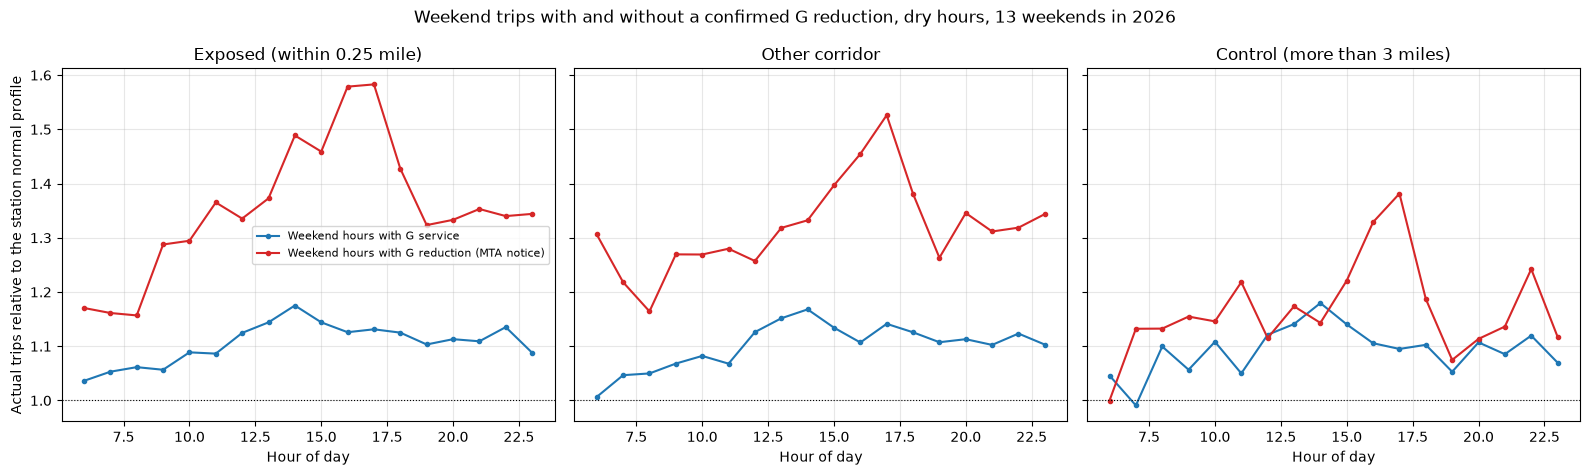

,actual to profile (service running),actual to profile (closure),station hours (service running),station hours (closure),closure to running ratio
group,,,,,
Control (more than 3 miles),1.100,1.182,35037.0,18187.0,1.074
Exposed (within 0.25 mile),1.116,1.391,31094.0,16078.0,1.247
Other corridor,1.113,1.336,31218.0,16168.0,1.200


Ratio of ratios, Exposed (within 0.25 mile) relative to control: 1.161
Ratio of ratios, Other corridor relative to control: 1.117
Closure weekends in the comparison: 24 days


In [9]:
# Weekend hours in 2026 with and without a confirmed G reduction, dry hours only, all model stations
weekend_all = panel_extended[
    panel_extended["period"].eq("2026") & panel_extended["station_active"] & panel_extended["is_weekend"] & ~panel_extended["is_holiday"]
    & panel_extended["hour_of_day"].between(6, 23) & ~panel_extended["precipitation_any"]
].copy()
closure_hour_set = sorted(weekend_all.loc[weekend_all["g_closure_hour"], "hour_of_day"].unique())
comparison = weekend_all[weekend_all["hour_of_day"].isin(closure_hour_set)].copy()
comparison["group"] = np.select(
    [comparison["exposed_station"], comparison["station_group"].eq("corridor")],
    ["Exposed (within 0.25 mile)", "Other corridor"], default="Control (more than 3 miles)",
)
# Ratio of actual trips to each station's normal profile for the same weekday and hour, summed over stations so large stations weigh more
comparison = comparison[comparison["profile_total_trips"].notna()]
def relative_level(frame):
    return frame["total_trips"].sum() / frame["profile_total_trips"].sum()
profile = (
    comparison.groupby(["group", "g_closure_hour", "hour_of_day"]).apply(relative_level, include_groups=False)
    .rename("relative_trips").reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
styles = [(False, "Weekend hours with G service", "tab:blue"), (True, "Weekend hours with G reduction (MTA notice)", "tab:red")]
for axis, group in zip(axes, ["Exposed (within 0.25 mile)", "Other corridor", "Control (more than 3 miles)"]):
    for closure_flag, label, color in styles:
        subset = profile[(profile["group"] == group) & (profile["g_closure_hour"] == closure_flag)]
        axis.plot(subset["hour_of_day"], subset["relative_trips"], marker="o", markersize=3, color=color, label=label)
    axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
    axis.set_title(group)
    axis.set_xlabel("Hour of day")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Actual trips relative to the station normal profile")
axes[0].legend(fontsize=8)
fig.suptitle("Weekend trips with and without a confirmed G reduction, dry hours, 13 weekends in 2026")
fig.tight_layout()
plt.show()

closure_summary = (
    comparison.groupby(["group", "g_closure_hour"]).apply(
        lambda frame: pd.Series({"actual to profile": relative_level(frame), "station hours": len(frame)}), include_groups=False)
    .unstack("g_closure_hour")
)
closure_summary.columns = [f"{stat} ({'closure' if flag else 'service running'})" for stat, flag in closure_summary.columns]
closure_summary["closure to running ratio"] = closure_summary["actual to profile (closure)"] / closure_summary["actual to profile (service running)"]
display(closure_summary.round(3))
ratio_control = closure_summary.loc["Control (more than 3 miles)", "closure to running ratio"]
for group in ("Exposed (within 0.25 mile)", "Other corridor"):
    print(f"Ratio of ratios, {group} relative to control: {closure_summary.loc[group, 'closure to running ratio'] / ratio_control:.3f}")
print(f"Closure weekends in the comparison: {comparison.loc[comparison['g_closure_hour'], 'hour'].dt.normalize().nunique()} days")




**Interpretation of Figure 6.** The figure shows actual trips relative to each station's normal profile, by hour of day, for weekend hours with and without a confirmed G reduction. Values above 1 mean more trips than the profile. Control stations more than 3 miles from the corridor move from 1.100 to 1.182 (ratio 1.074), which captures the general lift of closure weekends, for example from season and weather. Exposed stations within 0.25 mile move from 1.116 to 1.391 (ratio 1.247), and other corridor stations from 1.113 to 1.336 (ratio 1.200). Relative to control, the ratio of ratios is 1.161 for exposed stations and 1.117 for other corridor stations, so demand rose about 16 percent more near the closed segment than at control stations and the lift fades with distance. The comparison covers 24 closure days and uses dry hours only, so weather is held roughly constant. This agrees with the screening results in [Section 2.6](01_data_preparation.ipynb) (1.17 for 2026 weekends). It is a descriptive difference, not a causal estimate, because events and other weekend effects are not controlled. It motivates a count model with station, hour and weather controls.

## 3.7 Weather and the distribution of the outcome

Figure 7 relates weather to demand. Because demand depends strongly on the time of day, departures are expressed relative to the average for the same station, hour of day and day type before they are grouped by weather class. Figure 8 examines the distribution of hourly departures, because the choice of count model in the next stage depends on whether the variance is close to the mean.

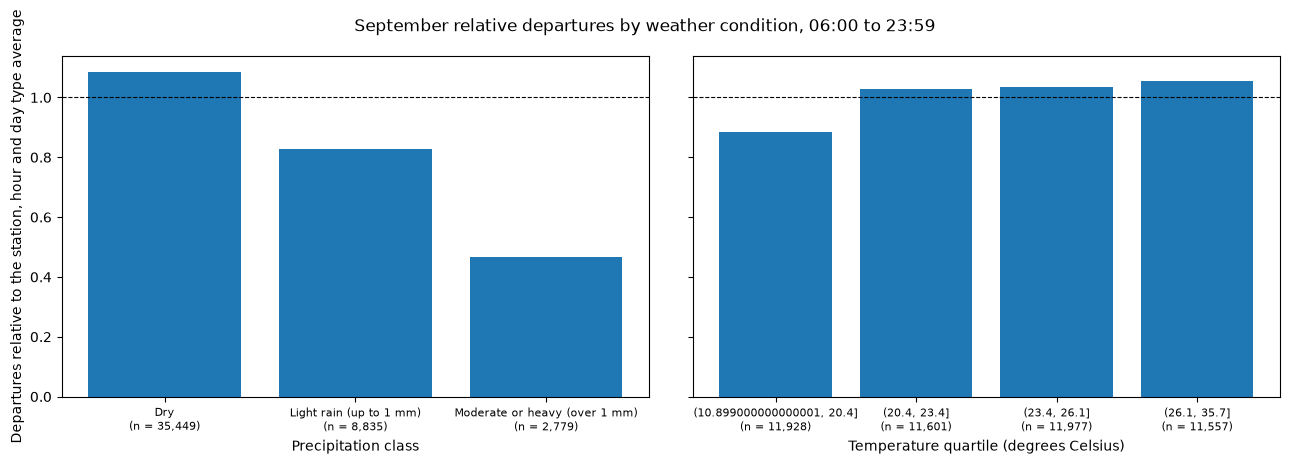

,mean,count
precipitation_class,,
Dry,1.084,35449
Light rain (up to 1 mm),0.829,8835
Moderate or heavy (over 1 mm),0.467,2779


Hours with any precipitation (all panel hours): 339


In [10]:
active = panel[panel["trip_observed"] & panel["hour_of_day"].between(6, 23)].copy()
expected_demand = active.groupby(["station_id", "hour_of_day", "is_weekend"])["departures"].transform("mean")
active["relative_departures"] = active["departures"] / expected_demand.replace(0, np.nan)
active["precipitation_class"] = np.select(
    [active["precipitation"].eq(0), active["precipitation"].le(1)],
    ["Dry", "Light rain (up to 1 mm)"],
    default="Moderate or heavy (over 1 mm)",
)
active["temperature_quartile"] = pd.qcut(active["temperature_2m"], 4)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for axis, column, order in (
    (axes[0], "precipitation_class", ["Dry", "Light rain (up to 1 mm)", "Moderate or heavy (over 1 mm)"]),
    (axes[1], "temperature_quartile", None),
):
    summary = active.groupby(column, observed=True)["relative_departures"].agg(["mean", "count"])
    if order:
        summary = summary.reindex(order)
    axis.bar(range(len(summary)), summary["mean"], color="tab:blue")
    axis.set_xticks(range(len(summary)))
    axis.set_xticklabels([f"{str(label)}\n(n = {int(n):,})" for label, n in zip(summary.index, summary["count"])], fontsize=8)
    axis.axhline(1, color="black", linewidth=0.8, linestyle="--")
    axis.set_xlabel("Precipitation class" if column == "precipitation_class" else "Temperature quartile (degrees Celsius)")
axes[0].set_ylabel("Departures relative to the station, hour and day type average")
fig.suptitle("September relative departures by weather condition, 06:00 to 23:59")
fig.tight_layout()
plt.show()

weather_summary = active.groupby("precipitation_class")["relative_departures"].agg(["mean", "count"]).round(3)
display(weather_summary)
print(f"Hours with any precipitation (all panel hours): {int((panel.drop_duplicates("hour")["precipitation"] > 0).sum())}")


**Interpretation of Figure 7.** Departures are scaled by the station, hour and day type average, so a value of 1 means typical demand. Dry hours average 1.08, light rain hours 0.83 and moderate or heavy rain hours 0.47. Demand falls steadily as precipitation rises, and the moderate or heavy class has far fewer observations (2,779) than the dry class (35,449). The rain effect is larger than the closure difference in Figure 6, so precipitation has to be kept as a control in any model, otherwise a rainy closure weekend could be mistaken for a closure effect. The weather grid is coarse relative to station locations, and the pattern is descriptive.

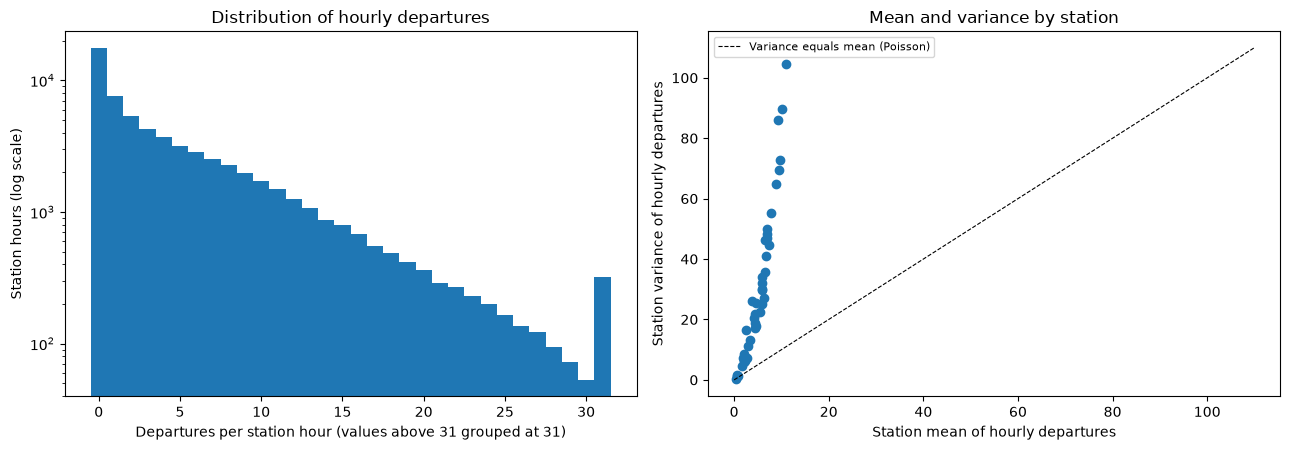

Mean departures per station hour: 4.994
Variance of departures per station hour: 38.084
Variance to mean ratio: 7.63
Share of station hours with zero departures: 28.0%
Median station level variance to mean ratio: 4.96


In [11]:
observed = panel[panel["trip_observed"]]
departures_mean = observed["departures"].mean()
departures_var = observed["departures"].var()
zero_share = observed["departures"].eq(0).mean()
station_moments = observed.groupby("station_id")["departures"].agg(["mean", "var"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
upper = int(observed["departures"].quantile(0.995))
axes[0].hist(observed["departures"].clip(upper=upper), bins=np.arange(0, upper + 2) - 0.5, color="tab:blue")
axes[0].set_yscale("log")
axes[0].set_xlabel(f"Departures per station hour (values above {upper} grouped at {upper})")
axes[0].set_ylabel("Station hours (log scale)")
axes[0].set_title("Distribution of hourly departures")
limit = float(station_moments[["mean", "var"]].max().max()) * 1.05
axes[1].scatter(station_moments["mean"], station_moments["var"], color="tab:blue")
axes[1].plot([0, limit], [0, limit], color="black", linestyle="--", linewidth=0.8, label="Variance equals mean (Poisson)")
axes[1].set_xlabel("Station mean of hourly departures")
axes[1].set_ylabel("Station variance of hourly departures")
axes[1].set_title("Mean and variance by station")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Mean departures per station hour: {departures_mean:.3f}")
print(f"Variance of departures per station hour: {departures_var:.3f}")
print(f"Variance to mean ratio: {departures_var / departures_mean:.2f}")
print(f"Share of station hours with zero departures: {zero_share:.1%}")
print(f"Median station level variance to mean ratio: {(station_moments['var'] / station_moments['mean']).median():.2f}")


**Interpretation of Figure 8.** The left panel shows the distribution of departures per station hour and the right panel the relation between the mean and the variance by station. Station hours average 4.99 departures with a variance of 38.08, a variance to mean ratio of 7.63, and 28.0 percent of station hours have zero departures. The median station level ratio is 4.96. A Poisson count has a ratio of 1, so the outcome is strongly overdispersed with excess zeros. This points toward a negative binomial or zero inflated count model, or a Poisson model with robust errors, rather than ordinary least squares on raw counts. Part of the overdispersion comes from the daily cycle and differences between stations, which later features will absorb, so the ratio is an upper bound on the dispersion that remains after modeling.

## 3.8 Dataset readiness for modeling

This section is the hand off to the modeling sections. It lists every ready table, says which one to start from, and gives the rules to follow before fitting anything. All ready tables are Delta tables in the project schema (default `workspace.citibike`), built from the raw files by the `citibike-prepare` job, which runs after each weekly download and can be started on its own. The raw downloads stay in the volume, and each raw reference file also has a `raw_` table.

### Where to start

For almost all modeling work, load one table: the extended panel. The other tables are lookups or summaries that explain how it was built.

```python
from citibike import data_access

panel = data_access.read_pandas("analysis_station_hour_panel_extended")
panel = panel[panel["station_active"]]                      # drop hours before a station opened or after it closed
train = panel[panel["split"] == "train"]                    # January to June 2026
valid = panel[panel["split"] == "validation"]               # July 2026
test = panel[panel["split"] == "test"]                      # August and September 2026
check_2024 = panel[panel["split"] == "validation_2024"]     # May to September 2024, external check
```

### Catalog of ready tables

| Table | Rows | Grain | Use it for |
|---|---|---|---|
| `analysis_station_hour_panel_extended` | 1,485,072 | station by clock hour, 153 stations | Main modeling table: outcomes, weather, calendar, shutdown flags, baseline, split. |
| `trip_hourly_model_stations` | 917,942 | station (`short_name`) by hour, only hours with trips | Intermediate hourly counts from the 58 million trip rows. Rebuild the panel from it; not needed for modeling. |
| `analysis_station_hour_panel` | 62,952 | station by hour, 43 Greenpoint stations, August and September 2026 | The [Section 2.5](01_data_preparation.ipynb) panel, the only one with Citi Bike status (bikes and docks available). |
| `mta_subway_shutdowns` | 118 | one event by one affected G stop | Shutdown table from the proposal: event id, type, stop, start and end time, nearby stations. |
| `model_station_sets` | 154 | station | Station lookup with `station_group` (94 corridor, 60 control) and distance to the nearest G stop. |
| `greenpoint_station_exposure` | 43 | Greenpoint station | Distance to the nearest affected stop, `exposed_station` and `distance_band`. |
| `g_service_closures_confirmed` | 4 | closure weekend | The August and September 2026 closure windows from MTA notices. |
| `g_service_closures_confirmed_pre_august` | 9 | closure weekend | The nine earlier 2026 closure weekends (`times_assumed` marks inferred times). |
| `g_service_reduction_windows_inferred` | 8 | window | Windows inferred from ridership, kept only as a cross check on the notices. |
| `baseline_accuracy_by_month` | 24 | month by station group | Error of the four week baseline, the reference every model should beat. |
| `shutdown_effect_screening` | 10 | event by group | Actual to profile demand ratio for each shutdown event, the descriptive effect behind Figure 6. |

`model_station_sets` has 154 rows because it includes station `JC124`, which has no trips and so is absent from the panels (153 stations).

### Keys and how to join

- `station_id` (GBFS identifier) and `hour` (naive New York local time) identify one row of every panel. The pair is unique.
- Trip files use the short station code `short_name` (for example `4665.02`). Status files and the [Section 2.5](01_data_preparation.ipynb) panel use `station_id`. `model_station_sets` maps one to the other. The extended panel carries both.
- `event_id` links the panel to `mta_subway_shutdowns`. There are 16 events: three 2024 phases (E01 to E03) and thirteen 2026 closure weekends.

### Extended panel columns

| Group | Columns | Meaning |
|---|---|---|
| Keys and design | `station_id`, `short_name`, `hour`, `period`, `split`, `station_group` | `period` is 2024 or 2026. `split` is chronological: `train` 655,944 rows, `validation` 112,344, `test` 221,064, `validation_2024` 495,720. `station_group` is `corridor` (within reach of the affected G segment, 94 stations) or `control` (59 stations with trips). |
| Outcomes | `departures`, `arrivals`, `total_trips`, `net_flow` | Hourly counts. `net_flow` is arrivals minus departures. Zero is filled for hours without trips. |
| Weather | `temperature_2m`, `precipitation`, `precipitation_any` | Hourly values from one Open Meteo grid cell, the same for all stations. |
| Calendar | `hour_of_day`, `hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`, `is_holiday` | The sine and cosine pair encodes the daily cycle. |
| Station attributes | `name`, `lat`, `lon`, `capacity`, `miles_to_nearest_g_stop` | From the latest station snapshot. |
| Shutdown flags | `g_closure_hour`, `exposed_closure_hour`, `event_id`, `event_type`, `event_exposed`, `distance_to_event_miles`, `exposed_station`, `exposed_station_2024`, `placebo_weekend_hour` | Whether the hour falls in a closure, whether the station is within a quarter mile of the affected stops, and the matching weekend hours with no closure used as placebo. |
| Reference demand | `baseline_departures`, `baseline_arrivals`, `baseline_total_trips`, `profile_departures`, `profile_arrivals`, `profile_total_trips` | `baseline_*` is the mean of the same hour in the previous four weeks, closure hours excluded, and needs at least two of them. `profile_*` is the mean per station, day of week and hour over a normal reference window. Both are expectations of normal demand, not outcomes. |
| Status | `bikes_available_mean`, `docks_available_mean`, `zero_bike_snapshots`, `zero_dock_snapshots`, `snapshot_count`, `status_observed`, `bikes_change`, `status_net_proxy`, `status_departure_proxy`, `status_arrival_proxy` | Filled only for the 43 Greenpoint stations after August 21, 2026 (about 3 percent of rows). `bikes_change` is the change in bikes available and the `status_*_proxy` columns are the demand proxies built from it. |
| Quality | `station_active` | False for 72,192 rows (4.9 percent) before a station's first trip or after its last. These zeros are not demand. |

The [Section 2.5](01_data_preparation.ipynb) panel keeps its own names for the same ideas (`zero_bike_share`, `zero_dock_share`, `departures_lag_24h`, `departures_lag_168h`, `nearest_affected_stop`, `nearest_affected_stop_miles`, `distance_band`, `trip_observed`). Use it when status data is the focus.

### Rules before modeling

1. Filter `station_active` to True before any fit or score. Figures 6, 9 and 10 and the baseline already do.
2. Never use `baseline_*`, `profile_*` or `status_*` columns as predictors of the same hour's outcome without checking leakage. The baseline uses only earlier weeks, but the profile uses the reference window and the status proxies are derived from the outcome.
3. Fit on `train`, tune on `validation`, report on `test`. Use `validation_2024` only to check that a shutdown effect also appears in a different year.
4. The baseline is missing for 253,793 of the 495,720 station hours in 2024 (the first four weeks of May, and hours whose earlier weeks fall in a closure or before a station opened). Check for missing values, or use the profile.
5. The outcome is a strongly overdispersed count (Figure 8), so start with a Poisson or negative binomial model and compare with the baseline errors in `baseline_accuracy_by_month`.
6. Treat the shutdown effect results as descriptive. Corridor and control stations differ in demand level, so compare ratios to the profile, as in Figure 6, and not raw counts.

### Known limitations

- 13 of the 16 closure weekends proposed were found in MTA notices. Eight of the earlier weekends use assumed times, and the 2024 phase dates come from web notices and use whole days.
- Station status covers only Greenpoint from August 21 to September 30, 2026, and three of the four August and September closure weekends overlap it.
- One weather grid cell serves all stations, and weather on closure weekends was not matched to comparison weekends.
- Station attributes come from the latest snapshot. Exposure uses distance to a stop, not ridership by station.
- Skipped stop work on the southern F and G section is not treated as a closure.
- Trip loading reads four fields only, so there is no outlier removal and no duplicate ride id check. Daylight saving transitions are assumed ignorable.

## 3.9 Exploration summary

The available data supports a descriptive baseline for 43 stations in the Greenpoint screening rectangle. September activity was higher than January, and the hourly profiles show different weekday and weekend peaks. Zero open docks were reported more often than zero bikes.

Four MTA Weekender notices (August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28) confirm a G suspension between Court Sq and Bedford-Nostrand Avs. Hourly ridership agrees with the notices: all inferred reduction hours fall inside the confirmed windows. Eight G stops are affected, and 14 of 43 stations lie within a quarter mile of one. The analysis panel (62,952 station hour rows from August 1 to September 30) joins trips, status, weather, exposure and closure flags. Figure 6 uses the extended panel, the 13 confirmed 2026 weekends and dry hours, and gives a ratio of ratios of 1.16 for exposed stations and 1.12 for other corridor stations relative to control. Rain lowers relative demand strongly (0.47 for moderate or heavy rain against 1.08 dry). Departures are overdispersed (variance to mean ratio 7.6, 28 percent zeros).

Limits: 13 of the 16 closure weekends were found (eight use assumed times), status starts on August 21, one weather cell serves all stations, and weather on closure weekends was not matched to comparison weekends. These results are descriptive and do not establish a causal effect. [Section 2.6](01_data_preparation.ipynb) extends the data to 153 stations, 14 trip months and 16 shutdown events, adds a four week baseline and a normal profile, and gives a screening result: demand at exposed stations relative to control stations is 1.01 on placebo weekends, 1.17 on confirmed 2026 closure weekends and 1.12 in 2024 phase 2. Next steps are to fit count models with station, hour and weather controls on the chronological split.

# 4. Model development

## 4.1 Modeling design

The model is a counterfactual demand forecaster. It learns normal hourly demand at each station from hours when the G train was running. During a closure it predicts what demand would have been with normal service. The ratio of actual to predicted demand at exposed stations, compared with control stations, measures how demand shifts during a disruption.

Design choices:

1. **Unit and target.** One station in one hour. The first target is `departures`; `arrivals` follows the same pipeline.
2. **Training data.** The `train` split (January to June 2026), active stations only, with every closure hour removed. A counterfactual model must never see disrupted hours, or it learns the effect it is supposed to measure.
3. **Tuning and testing.** Tune on `validation` (July 2026). Report accuracy on normal hours in `test` (August and September 2026). Closure hours in `test` are scored separately to estimate the disruption effect.
4. **Reference.** Every model must beat the four week baseline (`baseline_departures`).
5. **Predictors.** Only information known at forecast time: calendar, weather, station attributes and station identity. The `baseline_*`, `profile_*` and `status_*` columns are not used as predictors.

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path

panel = read_table("analysis_station_hour_panel_extended").sort_values(["short_name", "period", "hour"]).reset_index(drop=True)

# Rows before a station opened or after it closed are zeros, not demand
panel = panel[panel["station_active"]].copy()

# Closure hours: any hour inside a confirmed G closure window
closure = panel["g_closure_hour"].fillna(False).astype(bool)
panel["is_closure"] = closure

splits = ["train", "validation", "test", "validation_2024"]
summary = (
    panel.groupby(["split", "is_closure"])
    .size()
    .unstack(fill_value=0)
    .reindex(splits)
)
summary.columns = ["normal_hours", "closure_hours"]
print(summary)
print("\nStations:", panel["station_id"].nunique())
print("Station groups:\n", panel.drop_duplicates("station_id")["station_group"].value_counts())

                 normal_hours  closure_hours
split                                       
train                  549844          62095
validation              99697           7975
test                   182338          32230
validation_2024        265371         213330

Stations: 153
Station groups:
 station_group
corridor    94
control     59
Name: count, dtype: int64


## 4.2 Clean training data and the baseline to beat

Closure hours are removed from every split used to fit or tune the model. They are kept aside in `test_closure` to estimate the disruption effect later. The four week baseline (`baseline_departures`) is scored on the same normal hours as the models, so the comparison is fair. The baseline is missing when fewer than two of the previous four weeks are usable, so its coverage is reported with the error.

In [13]:
TARGET = "departures"

train_df = panel[(panel["split"] == "train") & ~panel["is_closure"]].copy()
valid_df = panel[(panel["split"] == "validation") & ~panel["is_closure"]].copy()
test_df = panel[(panel["split"] == "test") & ~panel["is_closure"]].copy()
test_closure = panel[(panel["split"] == "test") & panel["is_closure"]].copy()

print(f"train normal:  {len(train_df):,}")
print(f"valid normal:  {len(valid_df):,}")
print(f"test normal:   {len(test_df):,}")
print(f"test closure:  {len(test_closure):,}")

def score(y_true, y_pred):
    err = y_true - y_pred
    return {
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "mean_actual": y_true.mean(),
        "mean_pred": y_pred.mean(),
    }

def baseline_score(df, name):
    has_base = df["baseline_departures"].notna()
    result = score(df.loc[has_base, TARGET], df.loc[has_base, "baseline_departures"])
    result["coverage"] = has_base.mean()
    return pd.Series(result, name=name)

baseline_results = pd.concat(
    [baseline_score(valid_df, "validation"), baseline_score(test_df, "test")], axis=1
).T
print("\nFour week baseline on normal hours")
print(baseline_results.round(3))

print("\nTarget summary in train")
print(train_df[TARGET].describe().round(2))

train normal:  549,844
valid normal:  99,697
test normal:   182,338
test closure:  32,230

Four week baseline on normal hours
              MAE   RMSE  mean_actual  mean_pred  coverage
validation  1.652  2.971        2.952      3.076     0.995
test        1.622  2.863        3.255      3.198     0.993

Target summary in train
count    549844.00
mean          2.02
std           3.67
min           0.00
25%           0.00
50%           0.00
75%           2.00
max          62.00
Name: departures, dtype: float64


## 4.3 Poisson regression models

Departures are counts with many zeros and a long right tail (Figure 8), so the first models are Poisson regressions with a log link. Model A uses station identity, hour of day by day type, day of week, holidays and weather. Model B adds the logged four week baseline, which carries recent demand level and absorbs the seasonal rise from the January to June training months into July. The baseline is computed from earlier weeks with closure hours excluded, so it is available at forecast time and stays a valid input during a closure.

All models are fit on normal training hours with a baseline and scored on normal validation hours with a baseline.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor

def add_features(df):
    df = df.copy()
    df["hour_daytype"] = df["hour_of_day"].astype(str) + "_" + df["is_weekend"].astype(int).astype(str)
    df["temp_sq"] = df["temperature_2m"] ** 2
    df["is_holiday"] = df["is_holiday"].astype(int)
    df["precipitation_any"] = df["precipitation_any"].astype(int)
    df["log_baseline"] = np.log1p(df["baseline_departures"])
    return df

# Keep rows where the baseline exists, so every model is scored on the same hours
fit_df = add_features(train_df[train_df["baseline_departures"].notna()])
val_df = add_features(valid_df[valid_df["baseline_departures"].notna()])

CAT = ["station_id", "hour_daytype", "day_of_week"]
NUM_A = ["temperature_2m", "temp_sq", "precipitation", "precipitation_any", "is_holiday"]
NUM_B = NUM_A + ["log_baseline"]

def make_model(num_cols):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler(), num_cols),
    ])
    return Pipeline([("prep", prep), ("glm", PoissonRegressor(alpha=1e-4, max_iter=500))])

model_a = make_model(NUM_A).fit(fit_df[CAT + NUM_A], fit_df[TARGET])
model_b = make_model(NUM_B).fit(fit_df[CAT + NUM_B], fit_df[TARGET])

val_df["pred_a"] = model_a.predict(val_df[CAT + NUM_A])
val_df["pred_b"] = model_b.predict(val_df[CAT + NUM_B])

results_val = pd.DataFrame({
    "baseline": score(val_df[TARGET], val_df["baseline_departures"]),
    "poisson_A": score(val_df[TARGET], val_df["pred_a"]),
    "poisson_B": score(val_df[TARGET], val_df["pred_b"]),
}).T
print(f"Training rows: {len(fit_df):,}   Validation rows: {len(val_df):,}")
print(results_val.round(3))

Training rows: 485,815   Validation rows: 99,160
             MAE   RMSE  mean_actual  mean_pred
baseline   1.652  2.971        2.952      3.076
poisson_A  1.886  3.343        2.952      3.210
poisson_B  1.678  2.912        2.952      3.263


## 4.4 Gradient boosted Poisson model

Model B matched the baseline on RMSE but overpredicted July by about 10 percent, and Model A overpredicted more. A linear model in log space extrapolates temperature effects beyond the January to June training range. A gradient boosted tree model with a Poisson objective avoids this: tree predictions stay flat outside the observed range, and station by hour interactions are learned directly. The validation set is used for early stopping only.

In [15]:
import lightgbm as lgb

GBM_FEATURES = [
    "station_id", "hour_of_day", "is_weekend", "day_of_week", "is_holiday",
    "temperature_2m", "precipitation", "precipitation_any",
    "capacity", "lat", "lon", "log_baseline",
]
station_categories = pd.CategoricalDtype(sorted(panel["station_id"].unique()))

def gbm_frame(df):
    X = df[GBM_FEATURES].copy()
    X["station_id"] = X["station_id"].astype(station_categories)
    X["day_of_week"] = X["day_of_week"].astype(str).astype("category")
    return X

X_fit, X_val = gbm_frame(fit_df), gbm_frame(val_df)
X_val["day_of_week"] = X_val["day_of_week"].cat.set_categories(X_fit["day_of_week"].cat.categories)

gbm = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
)
gbm.fit(
    X_fit, fit_df[TARGET],
    eval_set=[(X_val, val_df[TARGET])],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
val_df["pred_gbm"] = gbm.predict(X_val, num_iteration=gbm.best_iteration_)

results_val.loc["lightgbm"] = score(val_df[TARGET], val_df["pred_gbm"])
print(f"Best iteration: {gbm.best_iteration_}")
print(results_val.round(3))

c:\Users\simon\OneDrive\Documents\GitHub\data622_nyc_bikes_project\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best iteration: 84
             MAE   RMSE  mean_actual  mean_pred
baseline   1.652  2.971        2.952      3.076
poisson_A  1.886  3.343        2.952      3.210
poisson_B  1.678  2.912        2.952      3.263
lightgbm   1.663  2.780        2.952      3.199


## 4.5 Counterfactual demand during G closures

The LightGBM model predicts what departures would have been with normal G service. For each station group, the demand ratio is total actual departures divided by total predicted departures. Stations are grouped as exposed (within a quarter mile of an affected G stop), other corridor, and control. Model bias common to all stations cancels in the ratio relative to control.

The same calculation on test weekends with no closure (placebo weekends) should give a relative ratio near 1. A closure ratio clearly above the placebo ratio indicates a shift in demand during the disruption.

In [16]:
def station_group_label(df):
    exposed = df["exposed_station"].fillna(False).astype(bool)
    return np.where(exposed, "exposed", np.where(df["station_group"] == "corridor", "other corridor", "control"))

def counterfactual_ratios(df, label):
    df = add_features(df[df["baseline_departures"].notna()])
    X = gbm_frame(df)
    X["day_of_week"] = X["day_of_week"].cat.set_categories(X_fit["day_of_week"].cat.categories)
    df["pred_gbm"] = gbm.predict(X, num_iteration=gbm.best_iteration_)
    df["group"] = station_group_label(df)
    out = df.groupby("group").agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"), station_hours=(TARGET, "size"))
    out["ratio"] = out["actual"] / out["predicted"]
    out["relative_to_control"] = out["ratio"] / out.loc["control", "ratio"]
    out.insert(0, "window", label)
    return out.reindex(["exposed", "other corridor", "control"]), df

placebo_df = test_df[test_df["placebo_weekend_hour"].fillna(False).astype(bool)]

closure_table, closure_scored = counterfactual_ratios(test_closure, "closure weekends")
placebo_table, placebo_scored = counterfactual_ratios(placebo_df, "placebo weekends")

effect_table = pd.concat([closure_table, placebo_table])
print(effect_table.round(3))

                          window  actual  predicted  station_hours  ratio  \
group                                                                       
exposed         closure weekends   37618  36293.909          10120  1.036   
other corridor  closure weekends   47119  46816.143          10120  1.006   
control         closure weekends    8581  12976.859          11880  0.661   
exposed         placebo weekends   48903  48097.727          12328  1.017   
other corridor  placebo weekends   62709  61875.045          12168  1.013   
control         placebo weekends   12623  16670.833          14366  0.757   

                relative_to_control  
group                                
exposed                       1.567  
other corridor                1.522  
control                       1.000  
exposed                       1.343  
other corridor                1.338  
control                       1.000  


The placebo check fails for the control group. Control stations lie 3 to 9 miles from the G (the Bronx, upper Manhattan, Bay Ridge, Queens and Jersey City), carry under one trip per hour, and are overpredicted by 25 to 35 percent even on normal weekends. Dividing by their ratio inflates every relative value, so the placebo gives 1.34 instead of 1.

Exposed and other corridor stations are fit well on placebo weekends (ratios 1.017 and 1.013), so other corridor stations are used as the comparison group. Closure ratio divided by placebo ratio is 1.019 for exposed stations and 0.993 for other corridor stations, which gives a relative shift of about 1.026. Departures near closed G stops run roughly 2 to 3 percent above the normal service counterfactual, relative to nearby corridor stations. Corridor stations may also respond to the closure, so this is likely a lower bound. The control group should be rebuilt from stations matched on distance and demand level.

# 5. Evaluation and validation

## 5.1 Effect by closure weekend

A pooled ratio can hide disagreement between events. The exposed to corridor ratio is computed separately for each of the four test closure weekends to show whether the shift is consistent.

In [17]:
closure_scored["weekend"] = closure_scored["event_id"]
per_weekend = (
    closure_scored[closure_scored["group"] != "control"]
    .groupby(["weekend", "group"])
    .agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"))
)
per_weekend["ratio"] = per_weekend["actual"] / per_weekend["predicted"]
per_weekend = per_weekend["ratio"].unstack("group")
per_weekend["exposed_vs_corridor"] = per_weekend["exposed"] / per_weekend["other corridor"]
print(per_weekend.round(3))

group    exposed  other corridor  exposed_vs_corridor
weekend                                              
E13        1.072           1.067                1.005
E14        1.151           1.117                1.031
E15        1.169           1.101                1.062
E16        0.549           0.536                1.025


## 5.2 Placebo distribution and the size of normal variation

Each normal weekend in validation and test gives one placebo value of the exposed to corridor ratio. Their spread shows how much the ratio varies without a closure. A closure effect is credible only if the closure weekends fall outside most of that spread.

In [18]:
placebo_all = pd.concat([
    valid_df[valid_df["placebo_weekend_hour"].fillna(False).astype(bool)],
    test_df[test_df["placebo_weekend_hour"].fillna(False).astype(bool)],
])
_, placebo_all_scored = counterfactual_ratios(placebo_all, "placebo")

# Shift by one day so Monday morning hours stay with their weekend
placebo_all_scored["weekend"] = (
    placebo_all_scored["hour"] - pd.Timedelta(days=1)
).dt.to_period("W").astype(str)

placebo_weekends = (
    placebo_all_scored[placebo_all_scored["group"] != "control"]
    .groupby(["weekend", "group"])
    .agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"))
)
placebo_weekends["ratio"] = placebo_weekends["actual"] / placebo_weekends["predicted"]
placebo_weekends = placebo_weekends["ratio"].unstack("group")
placebo_weekends["exposed_vs_corridor"] = placebo_weekends["exposed"] / placebo_weekends["other corridor"]

print(placebo_weekends.round(3))
print("\nPlacebo exposed_vs_corridor: mean {:.3f}, sd {:.3f}, n {}".format(
    placebo_weekends["exposed_vs_corridor"].mean(),
    placebo_weekends["exposed_vs_corridor"].std(),
    len(placebo_weekends),
))
print("Closure exposed_vs_corridor: mean {:.3f}, n {}".format(
    per_weekend["exposed_vs_corridor"].mean(), len(per_weekend)
))

group                  exposed  other corridor  exposed_vs_corridor
weekend                                                            
2026-06-29/2026-07-05    0.637           0.647                0.983
2026-07-13/2026-07-19    1.033           1.030                1.003
2026-07-20/2026-07-26    1.122           1.081                1.038
2026-07-27/2026-08-02    1.078           1.104                0.977
2026-08-10/2026-08-16    1.039           1.021                1.018
2026-08-24/2026-08-30    1.059           1.037                1.021
2026-08-31/2026-09-06    0.951           0.923                1.031
2026-09-14/2026-09-20    0.965           0.990                0.974

Placebo exposed_vs_corridor: mean 1.006, sd 0.025, n 8
Closure exposed_vs_corridor: mean 1.031, n 4


C:\Users\simon\AppData\Local\Temp\ipykernel_45372\3989724528.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  placebo_all_scored["hour"] - pd.Timedelta(days=1)


## 5.3 Is the closure shift larger than normal variation?

Two tests compare the four closure weekends with the eight placebo weekends. Welch's t test does not assume equal variance. The exact permutation test makes no distributional assumption: it relabels every possible set of four weekends out of twelve as closures (495 sets) and counts how often the difference in means is at least as large as the observed one. Both tests are one sided, because the hypothesis is that demand near closed stops rises.

In [19]:
from itertools import combinations
from scipy import stats

closure_vals = per_weekend["exposed_vs_corridor"].to_numpy()
placebo_vals = placebo_weekends["exposed_vs_corridor"].to_numpy()
observed_diff = closure_vals.mean() - placebo_vals.mean()

welch = stats.ttest_ind(closure_vals, placebo_vals, equal_var=False, alternative="greater")

pooled = np.concatenate([closure_vals, placebo_vals])
n_closure = len(closure_vals)
diffs = []
for idx in combinations(range(len(pooled)), n_closure):
    mask = np.zeros(len(pooled), dtype=bool)
    mask[list(idx)] = True
    diffs.append(pooled[mask].mean() - pooled[~mask].mean())
diffs = np.array(diffs)
perm_p = (diffs >= observed_diff - 1e-12).mean()

print(f"Closure mean {closure_vals.mean():.3f}   Placebo mean {placebo_vals.mean():.3f}")
print(f"Observed shift: {observed_diff * 100:.1f} percent")
print(f"Welch t = {welch.statistic:.2f}, one sided p = {welch.pvalue:.3f}")
print(f"Exact permutation p = {perm_p:.3f} ({len(diffs)} relabelings)")

Closure mean 1.031   Placebo mean 1.006
Observed shift: 2.5 percent
Welch t = 1.70, one sided p = 0.068
Exact permutation p = 0.065 (495 relabelings)


## 5.4 Accuracy on held out normal hours

The test split (August and September 2026) was not used for fitting or tuning. Models are scored on its normal hours with a baseline, overall and by station group, to check that the counterfactual is accurate where the effect is measured.

In [20]:
test_scored = add_features(test_df[test_df["baseline_departures"].notna()])
X_test = gbm_frame(test_scored)
X_test["day_of_week"] = X_test["day_of_week"].cat.set_categories(X_fit["day_of_week"].cat.categories)
test_scored["pred_gbm"] = gbm.predict(X_test, num_iteration=gbm.best_iteration_)
test_scored["pred_b"] = model_b.predict(test_scored[CAT + NUM_B])
test_scored["group"] = station_group_label(test_scored)

results_test = pd.DataFrame({
    "baseline": score(test_scored[TARGET], test_scored["baseline_departures"]),
    "poisson_B": score(test_scored[TARGET], test_scored["pred_b"]),
    "lightgbm": score(test_scored[TARGET], test_scored["pred_gbm"]),
}).T
print(f"Test normal hours: {len(test_scored):,}")
print(results_test.round(3))

by_group = test_scored.groupby("group").apply(
    lambda g: pd.Series({
        "baseline_RMSE": score(g[TARGET], g["baseline_departures"])["RMSE"],
        "lightgbm_RMSE": score(g[TARGET], g["pred_gbm"])["RMSE"],
        "actual_over_pred": g[TARGET].sum() / g["pred_gbm"].sum(),
    }),
    include_groups=False,
).reindex(["exposed", "other corridor", "control"])
print("\nBy station group")
print(by_group.round(3))

Test normal hours: 180,993
             MAE   RMSE  mean_actual  mean_pred
baseline   1.622  2.863        3.255      3.198
poisson_B  1.588  2.703        3.255      3.384
lightgbm   1.615  2.667        3.255      3.258

By station group
                baseline_RMSE  lightgbm_RMSE  actual_over_pred
group                                                         
exposed                 3.127          2.900             1.033
other corridor          3.700          3.449             1.034
control                 1.473          1.393             0.788


## 5.5 Evaluation summary and limitations

**Forecast accuracy.** On held out normal hours in August and September 2026, the LightGBM Poisson model has RMSE 2.667 against 2.863 for the four week baseline, an improvement of about 7 percent, with nearly no bias (mean prediction 3.258 against 3.255 actual). It beats the baseline in every station group. Poisson regression with the baseline as a feature also beats the baseline on test RMSE (2.703) but overpredicts by about 4 percent.

**Validity of the comparison.** On normal test hours the actual to predicted ratio is 1.033 for exposed stations and 1.034 for other corridor stations. The model errs the same way for both groups, so the exposed to corridor ratio isolates what differs between them during a closure. Control stations are overpredicted by about 21 percent (ratio 0.788) and are not used as a comparison.

**Disruption effect.** Across the four test closure weekends, departures at exposed stations relative to corridor stations average 1.031, against 1.006 on eight placebo weekends: a shift of about 2.5 percent. All four closure weekends are above 1, and one (E15, 1.062) exceeds every placebo weekend. The shift is about the size of normal weekend variation (placebo sd 0.025). Welch's t test gives one sided p = 0.068, and the exact permutation test gives p = 0.065. The evidence is suggestive but not significant at the 5 percent level.

**Limitations.**

1. Only four closure weekends are out of sample. Each new closure in the production period adds evidence.
2. Corridor stations may also respond to closures (E14 and E15 run 10 to 15 percent above prediction in both groups), so the relative shift is likely a lower bound on the local effect.
3. The control group (3 to 9 miles from the G, including Jersey City) is poorly fit and should be rebuilt from stations matched on distance and demand level.
4. One weather grid cell serves all stations, and the model missed weekend E16 by about half in every group, probably because of rain.
5. Eight of the earlier 2026 closure weekends use assumed times, which affects which training hours were removed.
6. Only departures are modeled. Arrivals and station availability (empty and full docks) are the next targets.

# 6. Production design and monitoring



# 7. Results and discussion



# 8. Conclusion



# 9. References and appendices

1. Citi Bike. Citi Bike System Data. https://citibikenyc.com/system-data
2. Citi Bike. Trip history archives for January, August and September 2026. https://s3.amazonaws.com/tripdata/202601-citibike-tripdata.zip, https://s3.amazonaws.com/tripdata/202608-citibike-tripdata.zip and https://s3.amazonaws.com/tripdata/202609-citibike-tripdata.zip
3. New York State Open Data. MTA Service Alerts: Beginning April 2020. https://data.ny.gov/resource/7kct-peq7.json. The API query retrieves New York City Transit Subway alert updates dated January 1 through October 1, 2026; the available records end August 11, 2026.
4. CUNY SPS Data Science. Citi Bike data pipeline. https://github.com/cuny-sps-datascience/citibike-data-pipeline. Reference supplied for project data collection and processing.

5. Google Cloud. BigQuery public datasets `bigquery-public-data.new_york_citibike.citibike_stations` (https://console.cloud.google.com/bigquery?project=eliot-463900&ws=!1m6!1m5!4m3!1sbigquery-public-data!2snew_york_citibike!3scitibike_stations!23sRESOURCE_LIST) and `bigquery-public-data.new_york_citibike.citibike_trips` (https://console.cloud.google.com/bigquery?project=eliot-463900&ws=!1m6!1m5!4m3!1sbigquery-public-data!2snew_york_citibike!3scitibike_trips!23sRESOURCE_LIST). The station status data (volume folder `datasource/station_status`, table `station_status_hourly`) is an NYC export partitioned by `nyc_date`; the file metadata (status poller version 1.2, Spark export job written on October 1, 2026) is recorded in the data sources document (`docs/data_sources.md`).
6. Open Meteo. Historical Weather API. https://open-meteo.com/en/docs/historical-weather-api. Hourly temperature and precipitation are requested for the Greenpoint station coordinates in January, August and September 2026. The returned grid coordinates are saved in a station weather lookup.
7. New York State Open Data. MTA Subway Stations. https://data.ny.gov/resource/39hk-dx4f.json. The export `MTA_Subway_Stations_20261003.csv` (table `raw_mta_subway_stations`) provides stop identifiers, route labels, names, and coordinates; stops with G service are selected from it.
8. MTA. MTA Weekender notices for August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28, 2026. https://www.mta.info/article/mta-weekender-august-7-10-2026, https://www.mta.info/article/mta-weekender-august-21-24-2026, https://www.mta.info/article/mta-weekender-september-11-14-2026 and https://www.mta.info/article/mta-weekender-september-25-28-2026
9. MTA. G line summer 2024 service change, June 28 to September 3, 2024, in three phases; and MTA Weekender notices for 2026 weekends with no G trains between Court Sq and Bedford-Nostrand Avs (February 27, March 6, 13, 20 and 27, April 17, June 5, June 19 and July 10), using the same URL pattern as reference 8. Citi Bike trip archives for May to September 2024 and February to July 2026 follow the pattern in reference 2.

Appendices can hold further data definitions, cleaning checks, and supplementary results.